# 06 · O modelo ampliado: mais domínios, mais evidência

**Objetivo:** a versão 2 da ontologia acrescenta capacidades, estados com transições, planos preventivos, sobressalentes, medições contra especificação, não conformidades, linha de base de energia, fornecedores e estoque. Este notebook mostra **o que cada acréscimo permite perguntar**, e volta à dúvida do notebook 04 (vedação ou tampa?) com evidência nova.

Regra usada para decidir o que entrou no modelo: **nenhuma classe sem uma pergunta de negócio que precise dela**. Cada seção abaixo é uma dessas perguntas.

### Antes de começar

| | |
|---|---|
| **Para quem** | Quem fez os notebooks 01 a 05 e quer ver como um modelo cresce sem virar um amontoado de classes. |
| **Pré-requisitos** | Notebooks 01 a 05 e um broker MQTT em `localhost:1883` (só a seção 8 precisa dele). |
| **Tempo** | 45 minutos |

**Ao final você consegue:**

- Justificar cada classe nova por uma pergunta de negócio que precisa dela.
- Ler uma consulta com dupla negação e traduzi-la como "para todo".
- Juntar evidências de manutenção, qualidade e estoque sobre o mesmo lote.
- Explicar o que um modelo de estados com transições permite detectar.

**Onde isso aparece na fábrica:** Toda ontologia industrial cresce. A diferença entre as que continuam úteis e as que viram um catálogo que ninguém usa está no critério para aceitar uma classe nova.

**Uma analogia para guardar:** Uma caixa de ferramentas boa não é a que tem mais ferramentas, é a que tem uma para cada serviço que aparece. Cada classe da versão 2 entrou porque havia um serviço esperando por ela.

> **Como estudar:** rode uma célula por vez. Sempre que aparecer **Pare e preveja**, responda mentalmente antes de executar. Errar a previsão é o que faz o conceito fixar.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID
from lab import queries as q, figures
import matplotlib.pyplot as plt
g = load_plant()

## 1. Capacidade: em quais linhas cada produto pode rodar?

O núcleo ganhou `Capability` (o que um equipamento **sabe fazer**) e a produção ganhou `requiresCapability` (o que um produto **exige**). Uma linha serve para um produto quando nenhuma capacidade exigida fica sem equipamento que a ofereça.

> **Pare e preveja.** Um produto exige três capacidades. Como dizer, numa consulta, que uma linha tem **todas** elas? SPARQL não tem um operador "para todo".

In [2]:
print(q.LINES_CAPABLE_OF_PRODUCT)
pd.DataFrame(query(g, q.LINES_CAPABLE_OF_PRODUCT))


SELECT ?product ?line WHERE {
  ?p a prd:Product ; rdfs:label ?product .
  ?l a mfg:Line ; rdfs:label ?line .
  FILTER NOT EXISTS {
    ?p prd:requiresCapability ?c .
    FILTER NOT EXISTS { ?eq mfg:partOf ?l ; mfg:hasCapability ?c }
  }
} ORDER BY ?product ?line



,product,line
0,Orange juice 1 l,Line 3
1,Still water 500 ml,Line 1
2,Still water 500 ml,Line 2
3,Still water 500 ml,Line 3


**Leitura:** a água de 500 ml roda nas três linhas. O suco de 1 l só roda na **linha 3**, a única com enchedora para garrafa de 1 l e tampadora de 38 mm. Para o planejamento isso significa que uma parada longa da linha 3 bloqueia o suco inteiro.

Repare na técnica da consulta: **dupla negação** (`FILTER NOT EXISTS` dentro de `FILTER NOT EXISTS`). Em português: "não existe capacidade exigida que não seja oferecida". É a forma de escrever "para todo" em SPARQL.

## 2. Preventiva: algum plano estava vencido no dia?

In [3]:
pd.DataFrame(query(g, q.overdue_plans()))

,plan,component,equipment,due,interval_days,stops_on_shift
0,PM-SEAL-L1,Seal Kit,Filler L1,2026-10-28 08:00:00+00:00,30,3


**Leitura:** o plano `PM-SEAL-L1` (troca do kit de vedação da enchedora da linha 1, a cada 30 dias) venceu em **28 de outubro**, treze dias antes do turno. E é justamente o componente por trás das três paradas por desgaste de vedação. A manutenção corretiva `MO-0077` trocou o kit **depois** das paradas; a preventiva teria trocado antes.

## 3. Sobressalentes: qual falha vista no turno não tem peça em estoque?

In [4]:
pd.DataFrame(query(g, q.SPARE_RISK))

,mode,component,spare,stock,stops
0,Motor overload,Main Motor,Main motor MTR-7,0,1


Houve uma parada por sobrecarga de motor, e o sobressalente do motor principal está com **estoque zero**. Hoje foram 9 minutos; se o motor falhar de vez, a parada dura o prazo de entrega da peça. Essa pergunta cruza três coisas que costumam estar em sistemas separados: o histórico de paradas, a árvore de componentes e o almoxarifado.

## 4. Qualidade: o torque das tampas contra a especificação

> **Pare e preveja.** Três lotes usaram a tampa ML-2207, e um deles (L-1041) rodou sem nenhuma parada por vedação. Se o problema fosse só a vedação da enchedora, como deveria estar o torque do L-1041?

In [5]:
torque = pd.DataFrame(query(g, q.TORQUE_VS_SPEC)).astype({"mean": float, "lowest": float, "samples": int, "out_of_spec": int})
torque

,lot,line,material_lot,lower,upper,samples,mean,lowest,out_of_spec
0,L-1041,Line 1,ML-2207,1.40,2.00,5,1.484,1.45,0
1,L-1042,Line 1,ML-2207,1.40,2.00,5,1.410,1.36,2
2,L-1043,Line 1,ML-2207,1.40,2.00,5,1.360,1.31,4
3,L-2041,Line 2,ML-2210,1.40,2.00,5,1.698,1.66,0
4,L-2042,Line 2,ML-2210,1.40,2.00,5,1.702,1.67,0
5,L-3041,Line 3,ML-2215,1.40,2.00,5,1.720,1.69,0


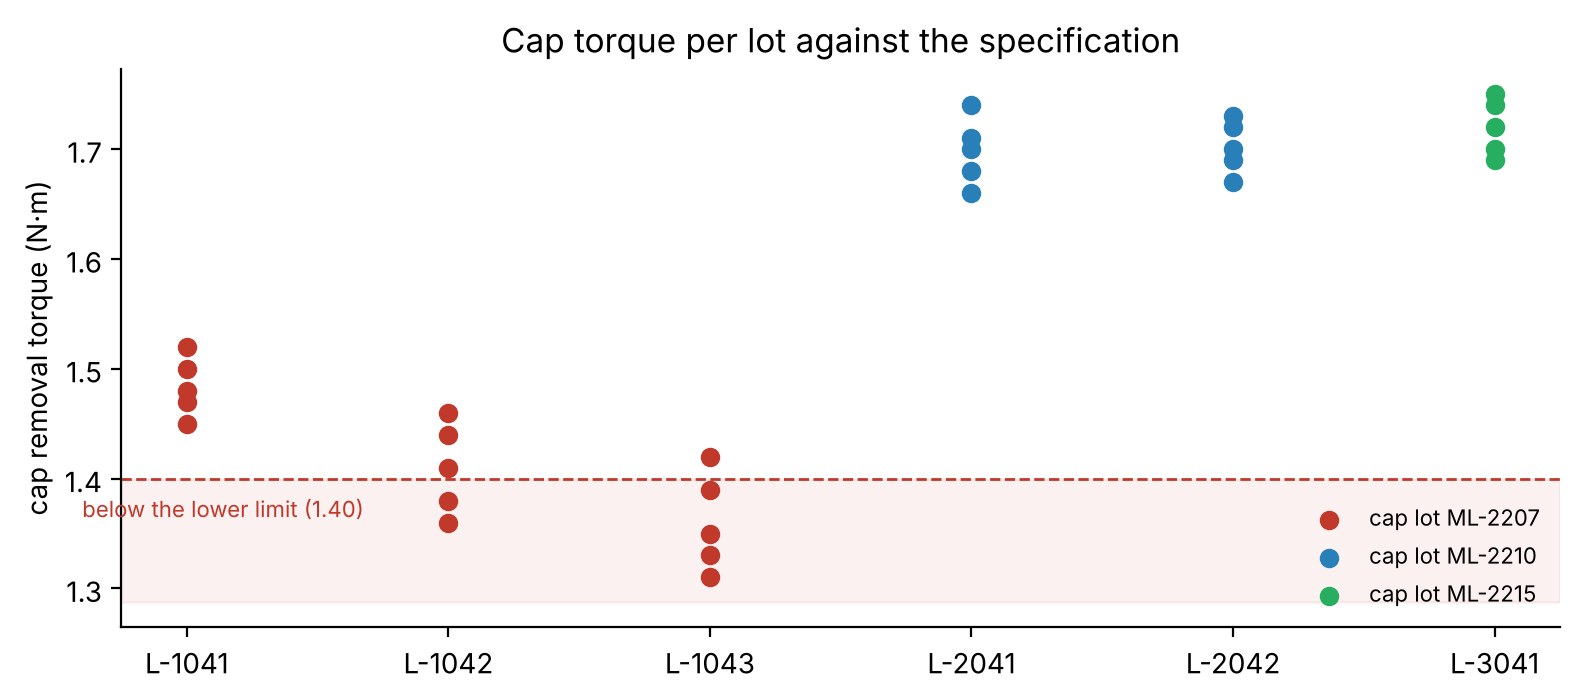

In [6]:
figures.torque(g); plt.show()

**Leitura:** a especificação pede torque de remoção entre 1,40 e 2,00 N·m. Os lotes que usaram tampas `ML-2210` e `ML-2215` ficam perto de 1,70. Os três lotes com tampa **`ML-2207`** ficam todos na parte de baixo da faixa, e dois deles têm amostras **fora** da especificação (2 de 5 e 4 de 5).

Isso é evidência nova para a pergunta do notebook 04. Vamos juntar tudo.

## 5. De volta à pergunta difícil: vedação ou tampa?

In [7]:
lotes = pd.DataFrame(query(g, q.LOTS_HIT_BY_FAILURE))[["lot", "result", "leaks", "stops_during_run"]]
quadro = lotes.merge(torque[["lot", "line", "material_lot", "mean", "out_of_spec"]], on="lot")
quadro.rename(columns={"mean": "torque_medio", "out_of_spec": "torque_fora", "stops_during_run": "paradas"})

,lot,result,leaks,paradas,line,material_lot,torque_medio,torque_fora
0,L-1041,PASS,4.0,0,Line 1,ML-2207,1.484,0
1,L-1042,HOLD,37.0,1,Line 1,ML-2207,1.410,2
2,L-1043,REJECT,61.0,3,Line 1,ML-2207,1.360,4
3,L-2041,PASS,1.0,0,Line 2,ML-2210,1.698,0
4,L-2042,PASS,NaN,1,Line 2,ML-2210,1.702,0
5,L-3041,PASS,2.0,1,Line 3,ML-2215,1.720,0


**O que mudou em relação ao notebook 04**

| Evidência | Aponta para |
|---|---|
| Vazamentos crescem com as paradas por vedação | enchedora (manutenção) |
| Plano preventivo do kit de vedação vencido há 13 dias | enchedora (manutenção) |
| Todos os lotes ruins usaram a tampa ML-2207 | tampa (material) |
| Torque baixo em **todos** os lotes com ML-2207, inclusive no L-1041, que não teve nenhuma parada | tampa (material) |

A última linha é a mais informativa: o lote `L-1041` rodou **sem parada nenhuma** e mesmo assim tem o torque mais baixo que os lotes das outras linhas. Isso enfraquece a hipótese de que só a vedação explica o problema.

**Mas continua sem veredito.** O torque também depende do cabeçote da tampadora da linha 1, e a ML-2207 só rodou nessa linha. O modelo ampliado **estreitou** as hipóteses e deixou o experimento mais barato: rodar um palete de ML-2207 na linha 2 e medir o torque responde em uma hora. Mais domínios no grafo significam mais evidência, não o fim da necessidade de experimentar.

## 6. Contenção: onde está o resto do material suspeito?

In [8]:
pd.DataFrame(query(g, q.STOCK_TO_QUARANTINE))

,material_lot,supplier,location,where,quantity,because_of
0,ML-2207,Cap Co,Warehouse rack A-03,São Paulo plant,12000,"NC-001, NC-002"
1,ML-2207,Cap Co,"Point of use, line 1",Line 1,1800,"NC-001, NC-002"


Enquanto a causa não é confirmada, a ação imediata é **segregar** o material. A consulta parte das não conformidades abertas, sobe pela genealogia até o lote de tampa e desce até o estoque: **13.800 tampas** em dois lugares, uma parte ainda no ponto de uso da linha 1, pronta para entrar na próxima ordem.

## 7. Energia: quem está fora da linha de base?

In [9]:
base = pd.DataFrame(query(g, q.ENERGY_VS_BASELINE))
base.assign(actual=base.actual.astype(float).round(2), deviation_pct=base.deviation_pct.astype(float).round(1))

,line,actual,expected,tolerance_pct,deviation_pct
0,Line 3,5.76,3.5,15.0,64.5
1,Line 1,3.45,3.5,15.0,-1.5
2,Line 2,3.16,3.5,15.0,-9.8


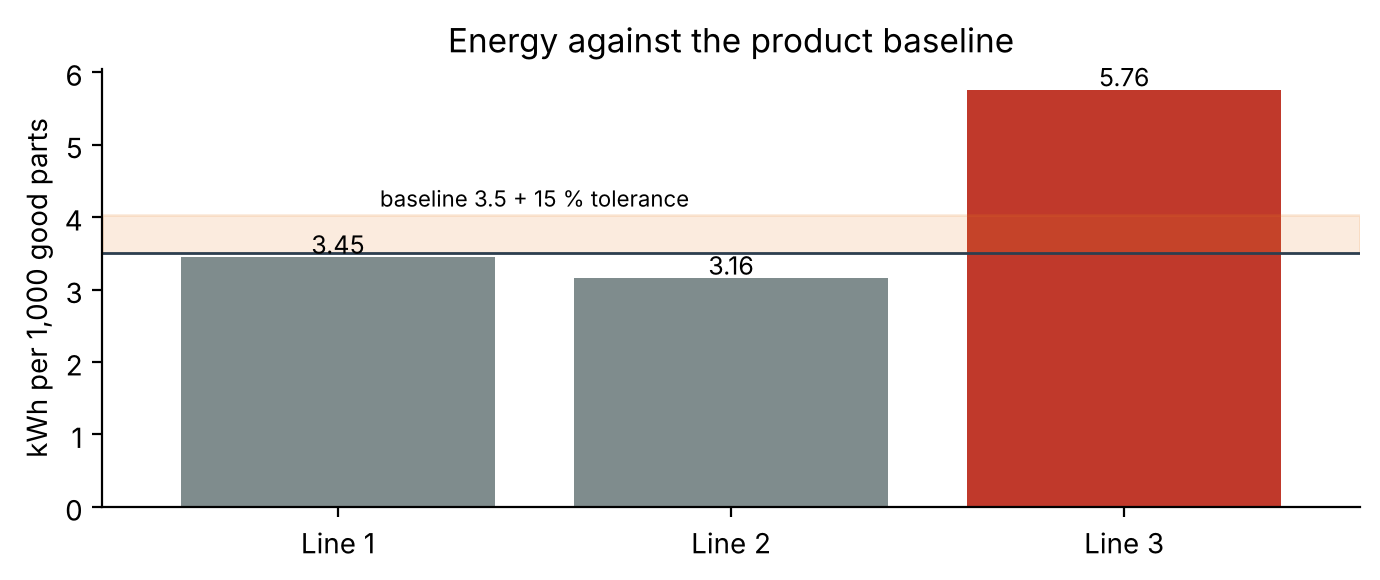

In [10]:
figures.baseline(g); plt.show()

No notebook 04 vimos que a linha 3 gasta mais por peça. Agora há um **critério**: a linha de base do produto é 3,5 kWh por mil garrafas, com 15 % de tolerância. As linhas 1 e 2 estão dentro; a linha 3 está **64 % acima**. Sem linha de base, "gasta mais" é uma observação. Com ela, é um desvio com dono e prazo.

## 8. Estados: o modelo sabe o que é impossível

O núcleo agora define quatro estados harmonizados e as transições permitidas. Uma máquina em `FAULTED` precisa ser **rearmada** (ir para `STOPPED`) antes de voltar a rodar.

In [11]:
pd.DataFrame(query(g, "SELECT ?de ?para WHERE { ?a a mfg:OperatingState ; rdfs:label ?de ; mfg:canTransitionTo/rdfs:label ?para } ORDER BY ?de ?para"))

,de,para
0,FAULTED,STOPPED
1,IDLE,RUNNING
2,IDLE,STOPPED
3,RUNNING,FAULTED
4,RUNNING,IDLE
5,RUNNING,STOPPED
6,STOPPED,IDLE
7,STOPPED,RUNNING


Ligamos a ponte do notebook 05 e deixamos o simulador publicar por 10 segundos. O simulador é ingênuo de propósito: às vezes manda uma máquina de `FAULTED` direto para `RUNNING`.

> **Pare e preveja.** O simulador às vezes manda uma máquina de FAULTED direto para RUNNING. Sem um modelo de estados, alguém perceberia? E com ele?

In [12]:
import socket, time, uuid
socket.create_connection(("localhost", 1883), timeout=2).close()
from lab.uns_bridge import UnsBridge, simulate_plant
vivo = load_plant()
ponte = UnsBridge(vivo, prefix=f"estudo-{uuid.uuid4().hex[:4]}")
ponte.start(); time.sleep(0.3)
simulate_plant(prefix=ponte.prefix, seconds=10, seed=7)
time.sleep(0.5); ponte.stop()
print(f"mudanças de estado registradas: {ponte.events_added}")
ilegais = pd.DataFrame(query(vivo, q.ILLEGAL_TRANSITIONS))
print(f"transições que o modelo considera impossíveis: {len(ilegais)}")
ilegais.assign(when=lambda d: pd.to_datetime(d.when).dt.strftime("%H:%M:%S")) if len(ilegais) else ilegais

mudanças de estado registradas: 9
transições que o modelo considera impossíveis: 1


,equipment,from,to,when
0,Filler L2,FAULTED,RUNNING,13:15:32


**Leitura:** cada linha é uma mudança que chegou pelo UNS e que **não existe** na lista de transições permitidas. Na prática isso costuma ser um destes problemas: o gateway perdeu uma mensagem intermediária, o CLP mapeia dois estados internos para o mesmo texto, ou a taxa de leitura é lenta demais para ver o rearme. Sem o modelo de estados, esses eventos entrariam no cálculo de disponibilidade sem ninguém perceber.

## 9. Os contratos novos

Cada classe nova que carrega uma regra de negócio ganhou um contrato SHACL. O arquivo `data/broken_v2.ttl` tem cinco registros errados, um por contrato.

In [13]:
from rdflib import Graph
from lab.graph import ROOT
from lab.validate import validate
sujo = Graph().parse(ROOT / "data" / "plant.ttl"); sujo.parse(ROOT / "data" / "broken_v2.ttl")
ok, violacoes = validate(sujo)
print("conforma:", ok, "| violações:", len(violacoes))
pd.DataFrame(violacoes)

conforma: False | violações: 8


,focus,path,message
0,maintenance-plan/PM-999,dueDate,A plan without a due date can never be overdue.
1,maintenance-plan/PM-999,intervalDays,The interval must be a positive number of days.
2,material-lot/ML-9999,suppliedBy,A material lot without a supplier cannot be traced back.
3,measurement/M-999,ofCharacteristic,A measurement must say which characteristic was measured.
4,measurement/M-999,value,A measurement needs exactly one numeric value.
5,non-conformance/NC-999,disposition,"Disposition must be UNDER_INVESTIGATION, REWORK, SCRAP or RELEASE."
6,specification/bad-torque,,The lower limit must be below the upper limit.
7,stock/S-999,quantity,Stock quantity cannot be negative.


Limites trocados numa especificação, medição em texto, disposição em texto livre, plano sem data, lote sem fornecedor e estoque negativo: todos barrados na entrada, cada um com a mensagem que diz o que corrigir.

## Resumo

* O modelo cresceu guiado por perguntas: **cada classe nova responde a algo** que antes exigia juntar sistemas na mão.
* Mais domínios trouxeram **mais evidência** para a mesma investigação, e mostraram o experimento mais barato.
* Estados com transições deixam o modelo **desconfiar do dado**, e não só guardá-lo.
* O notebook 07 mostra como tudo isso fica legível para uma pessoa nova no projeto e para um agente de IA.

---
## Erros comuns

- **Adicionar classe porque "pode ser útil".** Sem pergunta que precise dela, a classe fica vazia e confunde quem chega. Comece pela pergunta.
- **Tratar evidência nova como veredito.** O torque baixo aponta para a tampa, mas a tampadora da linha 1 também influencia. Mais evidência estreita, não encerra.
- **Guardar o estado como texto livre.** "Rodando", "RUN" e "running" viram três estados. Harmonize para um conjunto fechado e mantenha o texto original só como registro.
- **Linha de base sem tolerância.** Qualquer variação vira alarme. O desvio só importa além de uma faixa combinada.

## Teste seu entendimento

Responda antes de abrir cada resposta.

**1. Por que a consulta de capacidade usa dois `FILTER NOT EXISTS` aninhados?**

<details><summary>Ver resposta</summary>

Porque "a linha tem todas as capacidades exigidas" equivale a "não existe capacidade exigida que a linha não tenha". A dupla negação é a forma de escrever "para todo" em SPARQL.

</details>

**2. O lote L-1041 passou na inspeção. Por que ele é a peça mais informativa da investigação?**

<details><summary>Ver resposta</summary>

Porque rodou sem nenhuma parada por vedação e mesmo assim tem torque mais baixo que os lotes das outras linhas. Isso mostra que algo além da vedação está afetando a linha 1 ou a tampa ML-2207.

</details>

**3. O que uma transição FAULTED para RUNNING revela, se a máquina de verdade nunca faz isso?**

<details><summary>Ver resposta</summary>

Que o dado chegou incompleto ou mal traduzido: mensagem perdida, estados internos mapeados para o mesmo texto ou leitura lenta demais. É um problema de integração encontrado pelo modelo.

</details>

## Exercícios para praticar

1. Adicione ao modelo uma capacidade de rotulagem em manga (sleeve), exija-a num produto novo e veja em quais linhas ele pode rodar.
2. Mude a tolerância da linha de base para 70 %. A linha 3 ainda aparece como desvio? O que isso diz sobre escolher tolerâncias?
3. Escreva a consulta "quais planos preventivos vencem nos próximos 90 dias" a partir de `overdue_plans`.
4. Proponha a pergunta de negócio que justificaria uma classe `Shift` mais rica, com operador responsável.

## Glossário

| Termo | Significado |
|---|---|
| **Capacidade** | O que um equipamento sabe fazer, independente do produto. |
| **Dupla negação** | Padrão de consulta que expressa "para todo" como "não existe um que não". |
| **Plano preventivo** | Tarefa de manutenção recorrente, com intervalo e data de vencimento. |
| **Especificação** | Faixa aceita de uma característica para um produto. |
| **Não conformidade** | Registro formal de que um lote não atende aos requisitos, com a decisão tomada. |
| **Linha de base** | Valor esperado de um indicador, com a tolerância antes de virar desvio. |
| **Transição de estado** | Mudança de um estado operacional para outro; o modelo lista as que são possíveis. |

**Próximo passo:** [07 · Uma ontologia que pessoas e agentes de IA conseguem ler](07_ontologia_legivel_por_agentes.ipynb).